# Cold-gas (Nitrogen) hopper: sizing the tank, nozzle and thrust so the vehicle actually lifts

This notebook extends the blow-down model (Section 3.7: lumped reservoir, isentropic, choked / unchoked stages) into a **vehicle model**:

* tank mass from pressure, diameter, length and material (so the vehicle mass is no longer a free number),
* nozzle with optional diverging section (area ratio `eps`),
* optional **pressure regulator** (constant chamber pressure) instead of pure blow-down,
* 1-D vertical flight (thrust, weight, changing mass, gravity),
* sweeps to find the throat diameter / tank size that give the longest airborne time.

**Two facts that drive every design (derived in the notebook):**

1. Thrust and burn time are tied together by the gas you carry:
   $\;(F/W)\times t_{burn} \approx I_{sp}\times \zeta_{use}$, where $\zeta_{use}$ = usable gas mass / total vehicle mass.
   The throat diameter only chooses *how* this product is split between thrust and time. It cannot raise the product.
2. For a pressure vessel, gas mass / tank mass $\approx \dfrac{\sigma_{allow}/\rho_{mat}}{2RT}$ - it does **not** depend on pressure or size, only on the *material* (and on the fixed extra mass you bolt on).

Run the cells top to bottom. Change inputs in **Cell 1** only.

In [15]:
# ============ CELL 1 : INPUTS ============
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.optimize import brentq

# ---- gas (Nitrogen) and environment ----
gamma = 1.4
R     = 296.8          # J/(kg K)
g0    = 9.80665        # m/s^2
P_atm = 1.01325e5      # Pa
T_s1  = 300.0          # K   initial gas temperature in tank

# ---- storage tank ----
P_s1      = 20e5       # Pa   initial STORAGE pressure (20 bar)
D_in      = 0.0254       # m    tank internal diameter
L_cyl     = 0.50       # m    cylindrical length (hemispherical heads added on top)
material  = "Steel 4130"    # "Al6061-T6", "Steel 4130", "SS304", "COPV (effective)"
SF        = 2.5        # burst safety factor on ultimate strength
t_min     = 1.0e-3     # m    minimum practical wall thickness
fit_factor= 1.25       # extra mass factor for bosses, welds, fittings on the tank

# ---- everything else on the vehicle ----
m_other   = 0.30       # kg   valve + regulator + plumbing + nozzle + electronics + payload

# ---- nozzle ----
d_throat  = 4.0e-3     # m    throat diameter  (with eps = 1 this is also the exit, as in the book)
eps       = 1.0        # exit/throat area ratio (1 = converging only; 2-4 = bell)
P_reg     = None       # Pa   regulated chamber pressure, e.g. 15e5. None = pure blow-down (book model)

# ---- simulation ----
dt     = 1.0e-3        # s
t_max  = 40.0          # s

In [16]:
# ============ CELL 2 : TANK + VEHICLE MASS ============
MATERIALS = {   # (ultimate strength [Pa], density [kg/m^3])  -- rough handbook values, edit freely
    "Al6061-T6":        (290e6, 2700.0),
    "Steel 4130":       (670e6, 7850.0),
    "SS304":            (515e6, 8000.0),
    "COPV (effective)": (1500e6, 1700.0),   # carbon overwrap incl. liner knock-down, very approximate
}

def tank_props(D_in, L_cyl, P_s1, material, SF=SF, t_min=t_min, fit_factor=fit_factor):
    sig, rho = MATERIALS[material]
    Ri = D_in/2
    V  = np.pi*Ri**2*L_cyl + 4/3*np.pi*Ri**3                  # cylinder + 2 hemispherical heads
    t_cyl  = max(SF*P_s1*Ri/sig,     t_min)                   # hoop stress  t = SF P R / sigma
    t_head = max(SF*P_s1*Ri/(2*sig), t_min)                   # sphere       t = SF P R / 2 sigma
    vol_wall = 2*np.pi*Ri*L_cyl*t_cyl + 4*np.pi*Ri**2*t_head
    return V, fit_factor*rho*vol_wall, t_cyl

V, m_tank, t_wall = tank_props(D_in, L_cyl, P_s1, material)
rho_s1 = P_s1/(R*T_s1)
m_gas  = rho_s1*V
M0     = m_tank + m_other + m_gas

print(f"Tank volume        : {V*1e3:.2f} L      wall thickness {t_wall*1e3:.2f} mm")
print(f"Gas mass (N2)      : {m_gas*1e3:.1f} g")
print(f"Tank mass          : {m_tank*1e3:.1f} g   | other {m_other*1e3:.0f} g")
print(f"Lift-off mass M0   : {M0*1e3:.1f} g   -> weight {M0*g0:.2f} N")
print(f"Gas fraction       : {m_gas/M0*100:.1f} %   (gas / tank = {m_gas/m_tank:.2f})")

Tank volume        : 0.26 L      wall thickness 1.00 mm
Gas mass (N2)      : 5.9 g
Tank mass          : 411.4 g   | other 300 g
Lift-off mass M0   : 717.3 g   -> weight 7.03 N
Gas fraction       : 0.8 %   (gas / tank = 0.01)


In [17]:
# ============ CELL 3 : NOZZLE / THRUST MODEL ============
K_choke = (2/(gamma+1))**((gamma+1)/(2*(gamma-1)))       # mdot = Pc*At*sqrt(gamma/(R Tc))*K_choke
PR_crit = ((gamma+1)/2)**(gamma/(gamma-1))               # 1.893 -> choked if Pc > PR_crit*Patm

def area_ratio(M):
    return (1/M)*((2/(gamma+1))*(1+(gamma-1)/2*M**2))**((gamma+1)/(2*(gamma-1)))

def mach_from_eps(e):
    return 1.0 if e <= 1.0001 else brentq(lambda M: area_ratio(M)-e, 1.0000001, 12)

def mach_from_pr(pr):   # chamber / exit pressure ratio -> supersonic Mach
    return np.sqrt(2/(gamma-1)*(pr**((gamma-1)/gamma)-1))

def thrust_mdot(Pc, Tc, At, eps, Me_design, sep_limit=0.4):
    # Return (F, mdot, Ve, Pe) for chamber stagnation state (Pc, Tc).
    # Choked flow: ideal expansion in a fixed-area-ratio nozzle. If the exit would be over-expanded below
    # sep_limit*Patm, the flow is assumed to separate and the nozzle acts as if it ended where Pe = sep_limit*Patm.
    # Unchoked (Pc < PR_crit*Patm): subsonic, Pe = Patm, throat is the exit (the book's Stage II).
    if Pc <= P_atm:
        return 0.0, 0.0, 0.0, P_atm
    if Pc >= PR_crit*P_atm:
        mdot = Pc*At*np.sqrt(gamma/(R*Tc))*K_choke
        Me, Ae = Me_design, At*eps
        Pe = Pc*(1+(gamma-1)/2*Me**2)**(-gamma/(gamma-1))
        if Pe < sep_limit*P_atm:
            Pe = sep_limit*P_atm
            Me = mach_from_pr(Pc/Pe)
            Ae = At*area_ratio(Me)
        Te = Tc/(1+(gamma-1)/2*Me**2)
        Ve = Me*np.sqrt(gamma*R*Te)
        return mdot*Ve + (Pe-P_atm)*Ae, mdot, Ve, Pe
    Me = mach_from_pr(Pc/P_atm) if Pc > P_atm else 0.0
    Me = min(Me, 1.0)
    Te = Tc/(1+(gamma-1)/2*Me**2)
    Ve = Me*np.sqrt(gamma*R*Te)
    mdot = P_atm/(R*Te)*At*Ve
    return mdot*Ve, mdot, Ve, P_atm

# sanity check against the book model (A_e = 1 cm dia, 20 bar, 300 K): expect ~191 N, 360 g/s, 322 m/s
F_chk, md_chk, Ve_chk, _ = thrust_mdot(20e5, 300.0, np.pi/4*0.01**2, 1.0, 1.0)
print(f"check (1 cm exit, 20 bar): F = {F_chk:.1f} N, mdot = {md_chk*1e3:.1f} g/s, Ve = {Ve_chk:.1f} m/s, Isp = {F_chk/md_chk/g0:.1f} s")

check (1 cm exit, 20 bar): F = 191.2 N, mdot = 360.5 g/s, Ve = 322.3 m/s, Isp = 54.1 s


In [18]:
# ============ CELL 4 : FLIGHT SIMULATION (vertical, gravity, changing mass) ============
def simulate(D_in=D_in, L_cyl=L_cyl, P_s1=P_s1, material=material, m_other=m_other,
             d_throat=d_throat, eps=eps, P_reg=P_reg, T_s1=T_s1, dt=dt, t_max=t_max, record=True):
    V, m_tank, _ = tank_props(D_in, L_cyl, P_s1, material)
    m1 = P_s1/(R*T_s1)*V                      # initial gas mass
    At = np.pi/4*d_throat**2
    Me_d = mach_from_eps(eps)
    m = m1; M_dry = m_tank + m_other
    z = v = 0.0; t = 0.0
    t_lift = t_land = None; z_max = 0.0; t_pow = 0.0; airborne = False; TW0 = None
    rec = {k: [] for k in ["t","z","v","F","W","Pc","Ps","Tc","mdot","Ve","M"]}
    n = int(t_max/dt)
    for i in range(n):
        ratio = m/m1
        Ps = P_s1*ratio**gamma                # isentropic tank blow-down, Eq. 3.38 form
        Ts = T_s1*ratio**(gamma-1)
        Pc = Ps if P_reg is None else min(P_reg, Ps)
        F, mdot, Ve, _ = thrust_mdot(Pc, Ts, At, eps, Me_d)
        M = M_dry + m; W = M*g0
        if TW0 is None: TW0 = F/W
        if not airborne and F <= W:
            a = 0.0                           # sitting on the pad
            if P_reg is None and F < W and i > 0:
                break                         # blow-down thrust only falls: it will never lift off
        else:
            airborne = True
            a = (F - W)/M
        v += a*dt; z += v*dt
        if airborne and z <= 0.0 and v < 0.0:   # landed
            z = 0.0; v = 0.0; t_land = t
            if record: pass
            break
        if airborne and t_lift is None: t_lift = t
        if F > W: t_pow += dt
        m = max(m - mdot*dt, 0.0)
        z_max = max(z_max, z)
        if record:
            for k, val in zip(rec, [t, z, v, F, W, Pc, Ps, Ts, mdot, Ve, M]): rec[k].append(val)
        t += dt
        if m <= 0 or (mdot == 0.0 and not airborne): break
    out = dict(V=V, m_tank=m_tank, m_gas=m1, M0=M_dry+m1, TW0=TW0, z_max=z_max,
               t_lift=t_lift, t_land=t_land, t_air=(t_land - t_lift) if (t_land is not None and t_lift is not None) else
                                                    ((t - t_lift) if t_lift is not None else 0.0),
               t_powered=t_pow, landed=t_land is not None)
    if record:
        out["rec"] = {k: np.array(vv) for k, vv in rec.items()}
    return out

In [19]:
# ============ CELL 5 : RUN ONE DESIGN (the inputs of Cell 1) ============
res = simulate()
r = res["rec"]
Isp0 = r["F"][0]/(r["mdot"][0]*g0) if len(r["F"]) and r["mdot"][0] > 0 else float("nan")
zeta_use = res["m_gas"]*(1-(PR_crit*P_atm/P_s1)**(1/gamma))/res["M0"]

print(f"Thrust / weight at start    : {res['TW0']:.2f}")
print(f"Initial thrust              : {r['F'][0]:.2f} N   (weight {r['W'][0]:.2f} N)")
print(f"Initial mass flow           : {r['mdot'][0]*1e3:.2f} g/s,  Ve = {r['Ve'][0]:.0f} m/s,  Isp = {Isp0:.1f} s")
print(f"Time with thrust > weight   : {res['t_powered']:.2f} s")
print(f"Airborne time (lift-off->touchdown): {res['t_air']:.2f} s")
print(f"Max altitude                : {res['z_max']:.2f} m")
print(f"Burn ends (gas gone) at     : {r['t'][-1]:.2f} s")
print(f"Usable gas fraction (zeta)  : {zeta_use*100:.1f} % of lift-off mass")
print(f"Ideal HOVER bound  Isp*ln(M0/(M0-m_use)) with Isp0 = {Isp0:.0f} s : {Isp0*np.log(1/(1-zeta_use)):.1f} s")

Thrust / weight at start    : 4.35
Initial thrust              : 30.59 N   (weight 7.03 N)
Initial mass flow           : 57.67 g/s,  Ve = 322 m/s,  Isp = 54.1 s
Time with thrust > weight   : 0.11 s
Airborne time (lift-off->touchdown): 0.54 s
Max altitude                : 0.27 m
Burn ends (gas gone) at     : 0.54 s
Usable gas fraction (zeta)  : 0.7 % of lift-off mass
Ideal HOVER bound  Isp*ln(M0/(M0-m_use)) with Isp0 = 54 s : 0.4 s


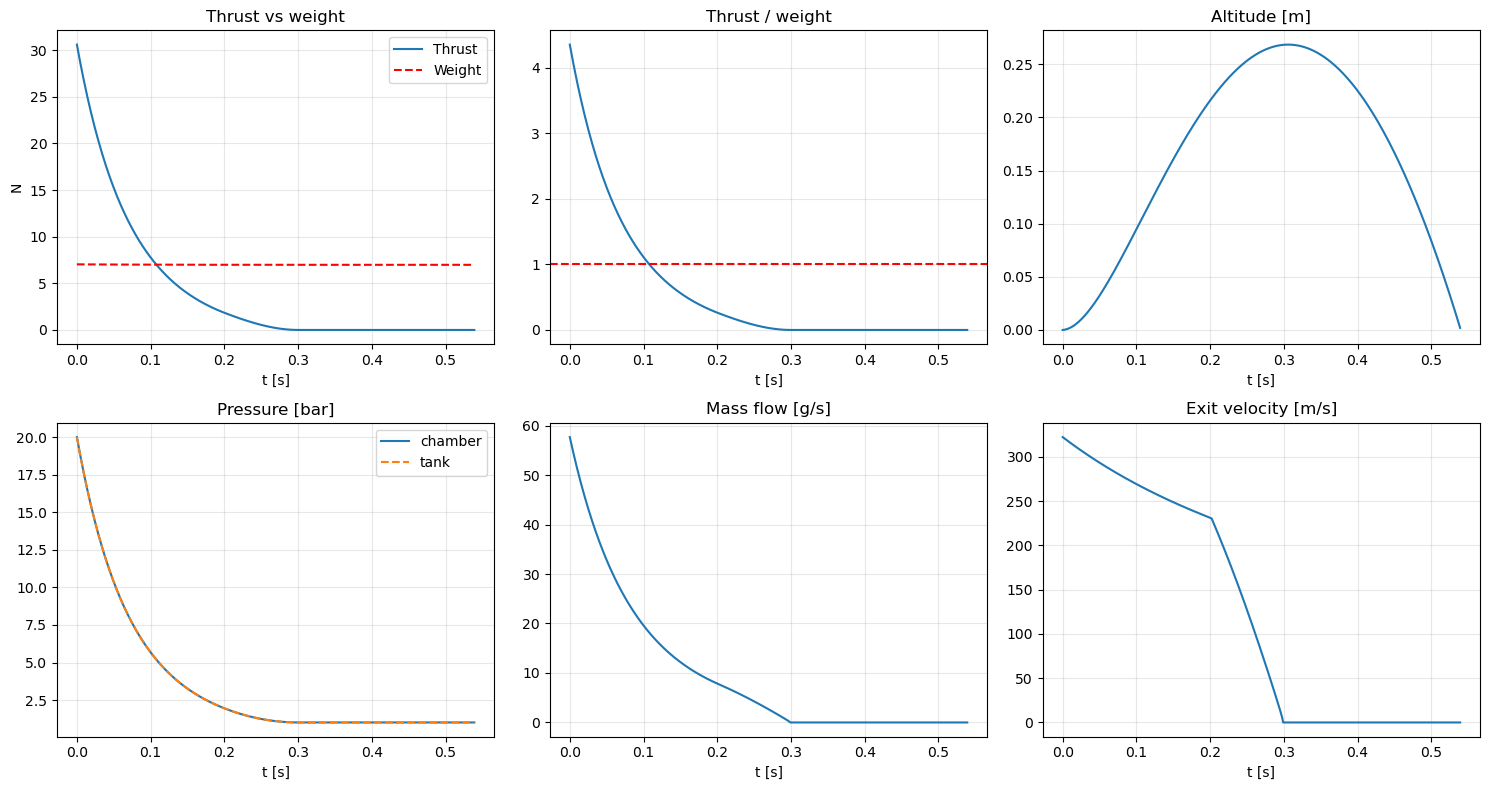

In [20]:
# ============ CELL 6 : PLOTS OF THIS DESIGN ============
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
t = r["t"]
ax[0,0].plot(t, r["F"], label="Thrust"); ax[0,0].plot(t, r["W"], "r--", label="Weight")
ax[0,0].set_title("Thrust vs weight"); ax[0,0].set_ylabel("N"); ax[0,0].legend()
ax[0,1].plot(t, r["F"]/r["W"]); ax[0,1].axhline(1, color="r", ls="--"); ax[0,1].set_title("Thrust / weight")
ax[0,2].plot(t, r["z"]); ax[0,2].set_title("Altitude [m]")
ax[1,0].plot(t, r["Pc"]/1e5, label="chamber"); ax[1,0].plot(t, r["Ps"]/1e5, "--", label="tank")
ax[1,0].set_title("Pressure [bar]"); ax[1,0].legend()
ax[1,1].plot(t, r["mdot"]*1e3); ax[1,1].set_title("Mass flow [g/s]")
ax[1,2].plot(t, r["Ve"]); ax[1,2].set_title("Exit velocity [m/s]")
for a in ax.ravel(): a.grid(alpha=.3); a.set_xlabel("t [s]")
plt.tight_layout(); plt.show()

,d_throat_mm,TW0,t_powered_s,t_air_s,z_max_m
0,1.5,0.61,0.00,0.00,0.00
1,2.0,1.09,0.02,0.07,0.00
2,2.5,1.70,0.10,0.34,0.04
3,3.0,2.45,0.12,0.46,0.13
4,3.5,3.33,0.12,0.51,0.21
5,4.0,4.35,0.11,0.54,0.27
6,4.5,5.50,0.10,0.56,0.31
7,5.0,6.80,0.09,0.57,0.34
8,5.5,8.22,0.08,0.58,0.37
9,6.0,9.79,0.07,0.59,0.38


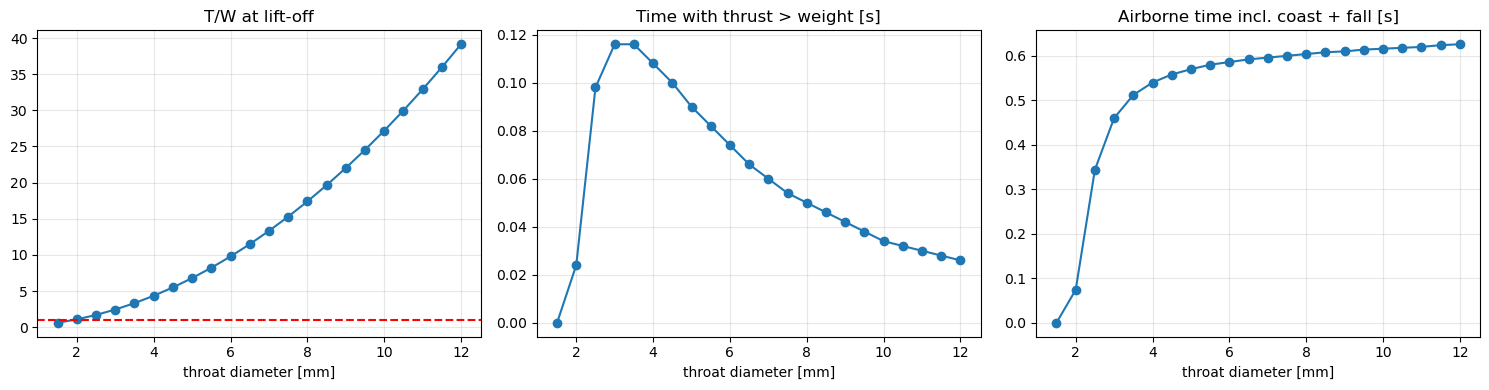

Longest sustained lift (thrust > weight): throat 3.00 mm -> 0.12 s, T/W0 = 2.45


In [21]:
# ============ CELL 7 : SWEEP THE THROAT DIAMETER (what the exit area really does) ============
d_list = np.linspace(1.5e-3, 12e-3, 22)
rows = []
for d in d_list:
    s = simulate(d_throat=d, dt=2e-3)
    rows.append(dict(d_throat_mm=d*1e3, TW0=s["TW0"], t_powered_s=s["t_powered"], t_air_s=s["t_air"], z_max_m=s["z_max"]))
sweep = pd.DataFrame(rows)
display(sweep.round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(sweep.d_throat_mm, sweep.TW0, "o-"); ax[0].axhline(1, color="r", ls="--"); ax[0].set_title("T/W at lift-off")
ax[1].plot(sweep.d_throat_mm, sweep.t_powered_s, "o-"); ax[1].set_title("Time with thrust > weight [s]")
ax[2].plot(sweep.d_throat_mm, sweep.t_air_s, "o-");   ax[2].set_title("Airborne time incl. coast + fall [s]")
for a in ax: a.set_xlabel("throat diameter [mm]"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
best = sweep.loc[sweep.t_powered_s.idxmax()]
print(f"Longest sustained lift (thrust > weight): throat {best.d_throat_mm:.2f} mm -> {best.t_powered_s:.2f} s, T/W0 = {best.TW0:.2f}")

In [8]:
# ============ CELL 8 : WHICH DESIGN LEVER HELPS?  (each case re-optimises the throat for the longest
# time with thrust > weight, keeping T/W0 >= 1.1) ============
def best_throat(d_lo=1.5e-3, d_hi=14e-3, n=28, objective="t_powered", min_TW=1.1, **kw):
    # scan the throat diameter; keep designs with T/W0 >= min_TW; maximise `objective`
    # objective: "t_powered" (time thrust > weight = sustained lift)  or  "t_air" (ballistic hop, any thrust)
    bestd, bests = None, None
    for d in np.linspace(d_lo, d_hi, n):
        s = simulate(d_throat=d, dt=2e-3, record=False, **kw)
        if s["TW0"] is None or s["TW0"] < min_TW: continue
        if bests is None or s[objective] > bests[objective]: bestd, bests = d, s
    return bestd, bests

cases = {
 "A  baseline (Cell-1 tank, blow-down, no bell)":        dict(),
 "B  + bell nozzle (eps = 4)":                           dict(eps=4.0),
 "C  + regulator (15 bar chamber, 60 bar storage)":      dict(P_s1=60e5, P_reg=15e5),
 "D  + regulator + bell":                                dict(P_s1=60e5, P_reg=15e5, eps=4.0),
 "E  D + light composite tank (COPV)":                   dict(P_s1=60e5, P_reg=15e5, eps=4.0, material="COPV (effective)"),
 "F  E at 200 bar storage":                              dict(P_s1=200e5, P_reg=15e5, eps=4.0, material="COPV (effective)"),
 "G  F + 3x bigger tank length (L = 1.5 m)":             dict(P_s1=200e5, P_reg=15e5, eps=4.0, material="COPV (effective)", L_cyl=1.5),
}
rows = []
for name, kw in cases.items():
    d, s = best_throat(**kw)
    if s is None:
        rows.append({"design": name, "best throat [mm]": np.nan}); continue
    rows.append({"design": name, "best throat [mm]": d*1e3, "M0 [kg]": s["M0"], "gas [g]": s["m_gas"]*1e3,
                 "gas/M0 [%]": s["m_gas"]/s["M0"]*100, "T/W0": s["TW0"],
                 "powered [s]": s["t_powered"], "airborne [s]": s["t_air"], "apex [m] (no drag)": s["z_max"]})
cmp_df = pd.DataFrame(rows)
display(cmp_df.round(2))

,design,best throat [mm],M0 [kg],gas [g],gas/M0 [%],T/W0,powered [s],airborne [s],apex [m] (no drag)
0,"A baseline (Cell-1 tank, blow-down, no bell)",3.81,1.04,99.97,9.65,2.74,1.44,5.92,24.01
1,B + bell nozzle (eps = 4),3.81,1.04,99.97,9.65,3.06,1.45,6.23,28.55
2,"C + regulator (15 bar chamber, 60 bar storage)",4.28,2.11,299.90,14.23,1.25,3.93,9.07,38.09
3,D + regulator + bell,4.28,2.11,299.90,14.23,1.35,3.98,9.99,54.52
4,E D + light composite tank (COPV),2.89,1.00,299.90,29.98,1.29,8.98,22.86,288.97
5,F E at 200 bar storage,3.81,1.92,999.68,51.99,1.17,20.27,40.00,1501.84
6,G F + 3x bigger tank length (L = 1.5 m),6.13,4.80,2763.83,57.59,1.21,21.98,40.00,2308.46


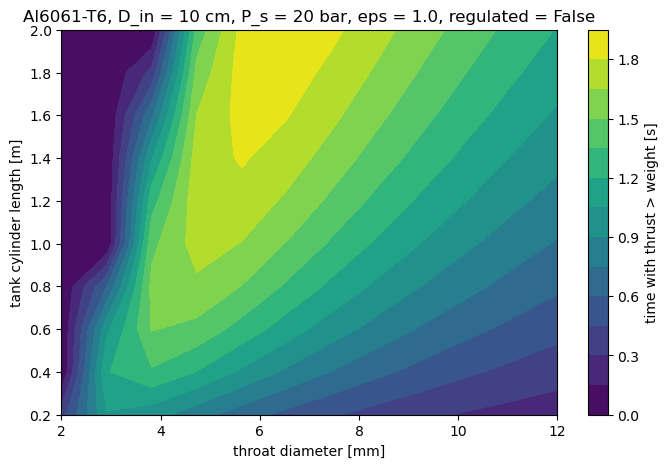

Best in map: L = 2.00 m, throat = 6.5 mm -> thrust > weight for 1.91 s


In [9]:
# ============ CELL 9 : MAP  tank length vs throat diameter  (time with thrust > weight, current Cell-1 settings) ============
L_list = np.linspace(0.2, 2.0, 10)
d_list = np.linspace(2e-3, 12e-3, 12)
Z = np.zeros((len(L_list), len(d_list)))
for i, L in enumerate(L_list):
    for j, d in enumerate(d_list):
        Z[i, j] = simulate(L_cyl=L, d_throat=d, dt=4e-3, record=False)["t_powered"]
plt.figure(figsize=(8, 5))
cs = plt.contourf(d_list*1e3, L_list, Z, levels=15); plt.colorbar(cs, label="time with thrust > weight [s]")
plt.xlabel("throat diameter [mm]"); plt.ylabel("tank cylinder length [m]")
plt.title(f"{material}, D_in = {D_in*100:.0f} cm, P_s = {P_s1/1e5:.0f} bar, eps = {eps}, regulated = {P_reg is not None}")
plt.show()
i, j = np.unravel_index(Z.argmax(), Z.shape)
print(f"Best in map: L = {L_list[i]:.2f} m, throat = {d_list[j]*1e3:.1f} mm -> thrust > weight for {Z[i,j]:.2f} s")